In [1]:
import xscen as xs
import xarray as xr
import figanos.matplotlib as fg
fg.utils.set_mpl_style('ouranos')
import xclim as xc
import glob
import pandas as pd
import numpy as np
import matplotlib
from pathlib import Path
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm
import cartopy.crs as ccrs
from matplotlib import gridspec
import copy
import sys
from matplotlib.patches import Rectangle
import os
import shapely
os.environ["QT_QPA_PLATFORM"] = "offscreen"  # prevent Qt kernel crash in Jupyter

import numpy as np
import itertools
import pandas as pd
from ete3 import Tree, TreeStyle, NodeStyle, TextFace, add_face_to_node
import xscen as xs
from IPython.display import Image, display
import geopandas as gpd
import matplotlib.patches as patches
import scipy
import matplotlib.colors as mcolors
color_dict = fg.utils.categorical_colors()
import itertools


pd.set_option('display.max_rows', None)

from xscen import CONFIG
xs.load_config(
    "../config/ARCHES/config_ARCHES.yml",
    "../config/ARCHES/paths_ARCHES.yml",
    reset=True,
)
cat_sim = xs.DataCatalog(CONFIG['extraction']['simulation']['search_data_catalogs']['data_catalogs'][0])

# CRCM5 mask
sfltf=cat_sim.search(source='CRCM5-SN', experiment='historical', variable='sftlf', driving_model='CanESM5').to_dataset(xarray_open_kwargs={'engine':'h5netcdf'})
mask = xs.regrid.create_mask(
                    sfltf,
                    **CONFIG["extraction"]["simulation"]["create_mask"],
                )
variables=['tasmax', 'tasmin','pr']
fe={ 'lakes':{'scale':'110m', 'edgecolor':'black', 'facecolor':'none'},'coastline':{'scale':'50m'}}

map_proj=ccrs.LambertConformal()
#map_proj=ccrs.RotatedPole(pole_longitude=87.59703130293302,pole_latitude=31.758312454493154,) # proj of casr

style_colors = matplotlib.rcParams["axes.prop_cycle"].by_key()["color"]
key_colors= {'CaSR':style_colors[0], 'raw':style_colors[1],'ESPO':style_colors[2],'Scaling':style_colors[3],}

    
months=['JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN',
          'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC']


if not Path(CONFIG['figures']).exists():
    Path(CONFIG['figures']).mkdir(parents=True, exist_ok=True)

#comes from availability
ids=['CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM4-8_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM4-8_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM4-8_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r8i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r4i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r1i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r2i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r3i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r4i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r8i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r3i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r2i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r1i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r2i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r3i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r1i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r4i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r8i1p1f2_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp585_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp585_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp585_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_AS-RCEC_TaiESM1_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_AS-RCEC_TaiESM1_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_AS-RCEC_TaiESM1_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CMCC_CMCC-ESM2_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CMCC_CMCC-ESM2_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CMCC_CMCC-ESM2_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r6i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-MM_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-MM_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-MM_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-MM_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NOAA-GFDL_GFDL-ESM4_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NOAA-GFDL_GFDL-ESM4_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NOAA-GFDL_GFDL-ESM4_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp585_r1i2p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp585_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp585_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp245_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp585_r6i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp585_r3i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp585_r2i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp245_r5i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp585_r1i1p1f2_global', 'CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp585_r2i1p1f2_global', 'CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp245_r1i1p1f2_global', 'CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp245_r2i1p1f2_global', 'CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r1i1p1f2_global', 'CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp245_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp585_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp585_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp585_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp245_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp585_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp585_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp585_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1_ssp585_r1i1p1f2_global', 'CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1_ssp370_r1i1p1f2_global', 'CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1_ssp245_r1i1p1f2_global', 'CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-ESM2-1_ssp245_r1i1p1f2_global', 'CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-ESM2-1_ssp370_r1i1p1f2_global', 'CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-ESM2-1_ssp585_r1i1p1f2_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r1i1p2f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r1i1p2f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r1i1p2f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5-1_ssp585_r1i1p2f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5-1_ssp370_r1i1p2f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5-1_ssp245_r1i1p2f1_global', 'CMIP6_ScenarioMIP_BCC_BCC-CSM2-MR_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_BCC_BCC-CSM2-MR_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_BCC_BCC-CSM2-MR_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp585_r6i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r6i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r9i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r11i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r6i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r11i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r9i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r6i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r9i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r11i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r1i1p1f1_global', 'CMIP6_CORDEX_CNRM-ESM2-1_r1i1p1f2_OURANOS_CRCM5-SN_ssp245_r1_NAM-12', 'CMIP6_CORDEX_CNRM-ESM2-1_r1i1p1f2_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp585_r1_NAM-12', 'CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp245_r1_NAM-12', 'CMIP6_CORDEX_NorESM2-MM_r1i1p1f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_NorESM2-MM_r1i1p1f1_OURANOS_CRCM5-SN_ssp245_r1_NAM-12', 'CMIP6_CORDEX_MPI-ESM1-2-LR_r5i1p1f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_MPI-ESM1-2-LR_r4i1p1f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_MPI-ESM1-2-LR_r1i1p1f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_MPI-ESM1-2-LR_r3i1p1f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_MPI-ESM1-2-LR_r2i1p1f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_MPI-ESM1-2-LR_r1i1p1f1_OURANOS_CRCM5-SN_ssp245_r1_NAM-12']
cat = xs.ProjectCatalog(f'{CONFIG['arches']}/cat_ARCHES.json')


/cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/MPI/gcc12/openmpi4/esmf/8.8.0/lib/python3.12/site-packages/esmpy/interface/loadESMF.py:94: VersionWarning: ESMF installation version 8.8.0, ESMPy version 8.8.0b0
  warnings.warn("ESMF installation version {}, ESMPy version {}".format(


In [5]:
import sys
import textwrap
from collections.abc import Callable
from inspect import Parameter, signature
from typing import cast

import numpy as np
import scipy.stats as spstats
import xarray as xr

from xclim.indices.generic import compare, detrend
from xclim.core.formatting import gen_call_string, update_xclim_history
from xclim.core.missing import MissingAny, MissingBase
SIGNIFICANCE_TESTS = {}


def significance_test(func: Callable) -> Callable:
    SIGNIFICANCE_TESTS[func.__name__[1:].replace("_", "-")] = func
    return func


def robustness_fractions(
    fut: xr.DataArray,
    ref: xr.DataArray | None = None,
    test: str | None = None,
    weights: xr.DataArray | None = None,
    invalid: MissingBase | None = None,
    strict_sign: bool = True,
    **kwargs,
) -> xr.Dataset:
        
    
    # Realization dimension name
    realization = "realization"

    # Assign dummy realization dimension if not present.
    if realization not in fut.dims:
        fut = fut.assign_coords({realization: "dummy"})
        fut = fut.expand_dims(realization)
    if ref is not None and realization not in ref.dims:
        ref = ref.assign_coords({realization: "dummy"})
        ref = ref.expand_dims(realization)

    # Get dummy weights to simplify code
    if weights is not None:
        w = weights
    else:
        w = xr.DataArray(
            [1] * fut[realization].size,
            dims=(realization,),
            coords={"realization": fut[realization]},
        )

    if ref is None:
        delta = fut
        valid = delta.notnull()
        if test not in [None, "threshold"]:
            raise ValueError("When deltas are given (ref=None), 'test' must be None or 'threshold'.")
    else:
        if invalid is None:
            invalid = MissingAny()
        delta = fut.mean("time") - ref.mean("time")
        valid = ~invalid(fut) & ~invalid(ref)
        #new
        if 'member' in delta.dims:
            delta=delta.mean('member')
            valid= valid.all(dim="member")

    if test is None:
        test_params = {}
        changed = xr.ones_like(delta).astype(bool)
        pvals = None
    elif test == "threshold":
        abs_thresh = kwargs.get("abs_thresh")
        rel_thresh = kwargs.get("rel_thresh")
        if abs_thresh is not None and rel_thresh is None:
            changed = abs(delta) > abs_thresh
            test_params = {"abs_thresh": abs_thresh}
        elif rel_thresh is not None and abs_thresh is None:
            changed = abs(delta / ref.mean("time")) > rel_thresh
            test_params = {"rel_thresh": rel_thresh}
        else:
            raise ValueError("One and only one of abs_thresh or rel_thresh must be given if test='threshold'.")
        pvals = None
    elif test in SIGNIFICANCE_TESTS:
        test_func = SIGNIFICANCE_TESTS[test]
        test_params = {
            n: kwargs.get(n, p.default)
            for n, p in signature(test_func).parameters.items()
            if p.kind == Parameter.KEYWORD_ONLY
        }
        changed, pvals = test_func(fut, ref, **test_params)
    else:
        raise ValueError(f"Statistical test {test} must be one of {', '.join(SIGNIFICANCE_TESTS.keys())}.")

    valid_frac = valid.weighted(w).sum(realization) / fut[realization].size
    n_valid = valid.weighted(w).sum(realization)
    change_frac = changed.where(valid).weighted(w).sum(realization) / n_valid
    if strict_sign:
        neg_del = compare(delta, "<", 0)
        pos_del = compare(delta, ">", 0)
    else:
        neg_del = compare(delta, "<=", 0)
        pos_del = compare(delta, ">=", 0)

    neg_frac = neg_del.where(valid).weighted(w).sum(realization) / n_valid
    pos_frac = pos_del.where(valid).weighted(w).sum(realization) / n_valid
    change_pos_frac = (pos_del & changed).where(valid).weighted(w).sum(realization) / n_valid
    change_neg_frac = (neg_del & changed).where(valid).weighted(w).sum(realization) / n_valid
    agree_frac = xr.concat((pos_frac, neg_frac, 1 - pos_frac - neg_frac), "sign").max("sign")

    # Metadata
    kwargs_str = gen_call_string("", **test_params)[1:-1]
    test_str = f"Significant change was tested with test {test} and parameters {kwargs_str}."

    strict = "strictly " if strict_sign else "zero or "
    out = xr.Dataset(
        {
            "changed": change_frac.assign_attrs(
                description=f"Fraction of valid members showing significant change. {test_str}",
                units="",
                test=str(test),
            ),
            "positive": pos_frac.assign_attrs(
                description=f"Fraction of valid members showing {strict} positive change.",
                units="",
            ),
            "changed_positive": change_pos_frac.assign_attrs(
                description=f"Fraction of valid members showing significant and {strict} positive change. {test_str}",
                units="",
                test=str(test),
            ),
            "negative": neg_frac.assign_attrs(
                description=f"Fraction of valid members showing {strict} negative change.",
                units="",
            ),
            "changed_negative": change_neg_frac.assign_attrs(
                description=f"Fraction of valid members showing significant and {strict} negative change. {test_str}",
                units="",
                test=str(test),
            ),
            "valid": valid_frac.assign_attrs(
                description="Fraction of valid members (No missing values along time).",
                units="",
            ),
            "agree": agree_frac.assign_attrs(
                description="Fraction of valid members agreeing on the sign of change. "
                + (
                    "Maximum between the positive, negative and no change fractions."
                    if strict_sign
                    else "Maximum between the zero or positive and the zero or negative change fractions."
                ),
                units="",
            ),
        },
        attrs={"description": "Significant change and sign of change fractions."},
    )
    out = out.fillna(0)

    if pvals is not None:
        pvals.attrs.update(
            description=f"P-values from change significance test. {test_str}",
            units="",
        )
        out = out.assign(pvals=pvals)

    # Keep attrs on non-modified coordinates
    for ncrd, crd in fut.coords.items():
        if ncrd in out.coords:
            out[ncrd].attrs.update(crd.attrs)

    return out


@significance_test
def _ipcc_ar6_c(fut, ref, *, ref_pi=None):
    r"""
    The advanced approach used in the IPCC Atlas chapter (:cite:t:`ipccatlas_ar6wg1`).

    Change is considered significant if the delta exceeds a threshold related to the internal variability.
    If pre-industrial data is given in argument `ref_pi`, the threshold is defined as
    :math:`\sqrt{2}*1.645*\sigma_{20yr}`, where :math:`\sigma_{20yr}` is the standard deviation of 20-year
    means computed from non-overlapping periods after detrending with a quadratic fit.
    Otherwise, when such pre-industrial control data is not available, the threshold is defined in relation to
    the historical data (`ref`) as :math:`\sqrt{\frac{2}{20}}*1.645*\sigma_{1yr}, where :math:`\sigma_{1yr}`
    is the inter-annual standard deviation measured after linearly detrending the data.
    See notebook :ref:`notebooks/ensembles:Ensembles` for more details.
    """
    # Ensure annual
    refy = ref.resample(time="YS").mean()
    if ref_pi is None:
        ref_detrended = detrend(refy, dim="time", deg=1)
        gamma = np.sqrt(2 / len(refy.time)) * 1.645 * ref_detrended.std("time")
    else:
        ref_detrended = detrend(refy, dim="time", deg=2)
        gamma = np.sqrt(2) * 1.645 * ref_detrended.resample(time="20YS").mean().std("time")

    delta = fut.mean("time") - ref.mean("time")
    changed = abs(delta) > gamma
    return changed, None

@significance_test
def _ipcc_ar6_c_old(fut, ref, *, ref_pi=None):
    r"""
    The advanced approach used in the IPCC Atlas chapter (:cite:t:`ipccatlas_ar6wg1`).

    Change is considered significant if the delta exceeds a threshold related to the internal variability.
    If pre-industrial data is given in argument `ref_pi`, the threshold is defined as
    :math:`\sqrt{2}*1.645*\sigma_{20yr}`, where :math:`\sigma_{20yr}` is the standard deviation of 20-year
    means computed from non-overlapping periods after detrending with a quadratic fit.
    Otherwise, when such pre-industrial control data is not available, the threshold is defined in relation to
    the historical data (`ref`) as :math:`\sqrt{\frac{2}{20}}*1.645*\sigma_{1yr}, where :math:`\sigma_{1yr}`
    is the inter-annual standard deviation measured after linearly detrending the data.
    See notebook :ref:`notebooks/ensembles:Ensembles` for more details.
    """
    # Ensure annual
    refy = ref.resample(time="YS").mean()
    if ref_pi is None:
        ref_detrended = detrend(refy, dim="time", deg=1)
        gamma = np.sqrt(2 / 20) * 1.645 * ref_detrended.std("time")
    else:
        ref_detrended = detrend(refy, dim="time", deg=2)
        gamma = np.sqrt(2) * 1.645 * ref_detrended.resample(time="20YS").mean().std("time")

    delta = fut.mean("time") - ref.mean("time")
    changed = abs(delta) > gamma
    return changed, None

@significance_test
def _small_ens_test(fut, ref,):
    r"""
    Based on eq 9 in martin's doc
    """
    # Ensure annual
    refy = ref.resample(time="YS").mean()
    futy = fut.resample(time="YS").mean()
    nref = len(refy.time) * len(ref.member) if "member" in refy.dims else len(refy.time)
    nfut = len(futy.time) * len(fut.member) if "member" in refy.dims else len(refy.time)

    ref_detrended = detrend(refy, dim="time", deg=1)
    fut_detrended = detrend(futy, dim="time", deg=1)

    ref_var=  ref_detrended.var(["time",'member'])
    fut_var=  fut_detrended.var(["time",'member'])
    
    gamma = 1.645 * np.sqrt((ref_var/nref) + (fut_var/nfut))

    delta = (fut.mean("time") - ref.mean("time")).mean('member')
    changed = abs(delta) > gamma
    return changed, None


# split ensemble in sub_ids and member

In [3]:
import re
import pandas as pd
import xarray as xr

import re
import pandas as pd
import xarray as xr
from collections import defaultdict

def stack_ensemble_member(ens, dim="realization"):
    pattern = re.compile(r'_(r\d+i\d+p\d+f\d+)_?')  # rXiYpZfW anywhere, optional trailing underscore
    
    sub_ids = []
    for r in ens[dim].values.astype(str):
        m = pattern.search(r)
        if not m:
            raise ValueError(f"No _rXiYpZfW_ pattern found in '{r}'")
        sub_id = r[:m.start()] +'_'+ r[m.end():]  # everything except the matched block
        sub_ids.append(sub_id)
    
    # count occurrences of each sub_id, in order of appearance
    counters = defaultdict(int)
    numbers = []
    for s in sub_ids:
        numbers.append(counters[s])
        counters[s] += 1
    
    midx = pd.MultiIndex.from_arrays([sub_ids, numbers], names=["sub_id", "member"])
    ens = ens.assign_coords({dim: midx}).unstack(dim)
    ens=ens.rename({'sub_id':'realization'})
    return ens




# compare methods

In [6]:
idsnomem=[
    'ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_CORDEX_MPI-ESM1-2-LR_*_OURANOS_CRCM5-SN_ssp370_r1_NAM'
]
# all_ids=[]
# for sim_id in idsnomem:
#     dss_for_this_id=[]
#     for f in glob.glob(f"{CONFIG['arches']}/rx1day/espo/rx1day_{sim_id}_espo.zarr.zip"):
#         ds= xr.open_zarr(f)
#         datetime_index = ds.indexes['time'].to_datetimeindex()
#         ds['time'] = datetime_index
#         dss_for_this_id.append(ds)
#     ens_id=xr.concat(dss_for_this_id, dim='member')
#     ens_id=ens_id.expand_dims(realization=[sim_id])
#     all_ids.append(ens_id)
# ens=xr.concat(all_ids, dim='realization')


d={}
for sim_id in idsnomem:
    for f in glob.glob(f"{CONFIG['arches']}/rx1day/espo/rx1day_{sim_id}_espo.zarr.zip"):
        ds= xr.open_zarr(f)
        d[ds.attrs['cat:id']]=ds
ens2=xc.ensembles.create_ensemble(d)
ens2 = stack_ensemble_member(ens2)
display(ens2)

pref="1991-2020"
pfut='2071-2100'

/tmp/ipykernel_2337795/892814870.py:29: FutureWarning: the `pandas.MultiIndex` object(s) passed as 'realization' coordinate(s) or data variable(s) will no longer be implicitly promoted and wrapped into multiple indexed coordinates in the future (i.e., one coordinate for each multi-index level + one dimension coordinate). If you want to keep this behavior, you need to first wrap it explicitly using `mindex_coords = xarray.Coordinates.from_pandas_multiindex(mindex_obj, 'dim')` and pass it as coordinates, e.g., `xarray.Dataset(coords=mindex_coords)`, `dataset.assign_coords(mindex_coords)` or `dataarray.assign_coords(mindex_coords)`.


<xarray.Dataset> Size: 1GB
Dimensions:       (realization: 12, member: 5, rlat: 189, rlon: 162, time: 150)
Coordinates:
  * realization   (realization) object 96B 'ESPO_CaSR_CMIP6_CORDEX_MPI-ESM1-2...
  * member        (member) int64 40B 0 1 2 3 4
  * rlat          (rlat) float32 756B -11.52 -11.43 -11.34 ... 5.22 5.31 5.4
  * rlon          (rlon) float32 648B 6.633 6.723 6.813 ... 20.94 21.03 21.12
    lat           (rlat, rlon) float32 122kB dask.array<chunksize=(10, 10), meta=np.ndarray>
    lon           (rlat, rlon) float32 122kB dask.array<chunksize=(10, 10), meta=np.ndarray>
    mask          (rlat, rlon) float64 245kB dask.array<chunksize=(10, 10), meta=np.ndarray>
    orog          (rlat, rlon) float32 122kB dask.array<chunksize=(10, 10), meta=np.ndarray>
  * time          (time) object 1kB 1951-01-01 00:00:00 ... 2100-01-01 00:00:00
    rotated_pole  int32 4B 1
Data variables:
    rx1day        (time, rlat, rlon, realization, member) float32 1GB dask.array<chunksize=(150, 10, 10, 1, 1), meta=np.ndarray>
Attributes: (12/32)
    avertissement:                Ouranos ne donne aucune garantie, expresse ...
    cat:_data_format_:            zarr
    cat:activity:                 ScenarioMIP
    cat:bias_adjust_institution:  Ouranos
    cat:bias_adjust_project:      ESPO
    cat:bias_adjust_reference:    CaSR
    ...                           ...
    intake_esm_dataset_key:       ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_s...
    intake_esm_vars:              ['pr']
    license:                      Creative Commons Attribution 4.0 Internatio...
    organisation:                 Équipe science du climat et services climat...
    organization:                 Climate Science and Climate Services Team, ...
    version:                      v2.0

/tmp/ipykernel_2337795/892814870.py:29: FutureWarning: the `pandas.MultiIndex` object(s) passed as 'realization' coordinate(s) or data variable(s) will no longer be implicitly promoted and wrapped into multiple indexed coordinates in the future (i.e., one coordinate for each multi-index level + one dimension coordinate). If you want to keep this behavior, you need to first wrap it explicitly using `mindex_coords = xarray.Coordinates.from_pandas_multiindex(mindex_obj, 'dim')` and pass it as coordinates, e.g., `xarray.Dataset(coords=mindex_coords)`, `dataset.assign_coords(mindex_coords)` or `dataarray.assign_coords(mindex_coords)`.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/

Text(0.5, 1.0, 'rx1day.\n small_ens_test. all members for for 12 models .\n ssp370. 2071-2100 vs.1991-2020')

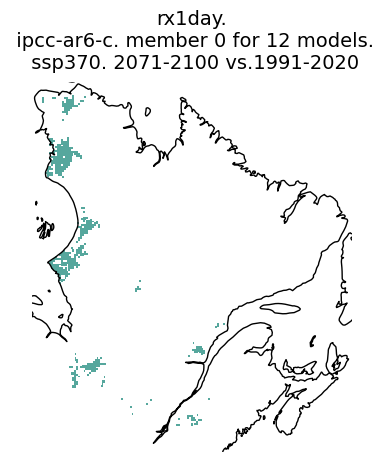

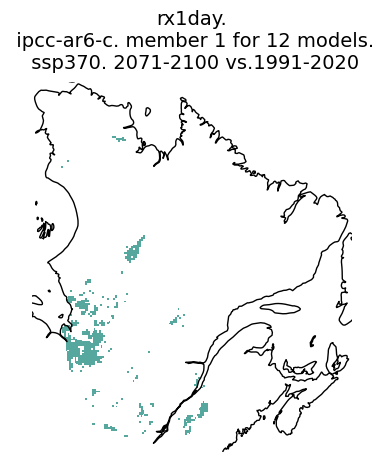

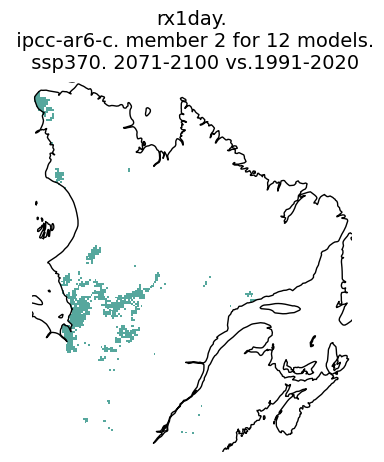

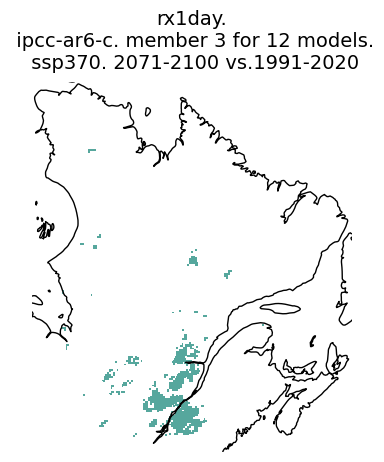

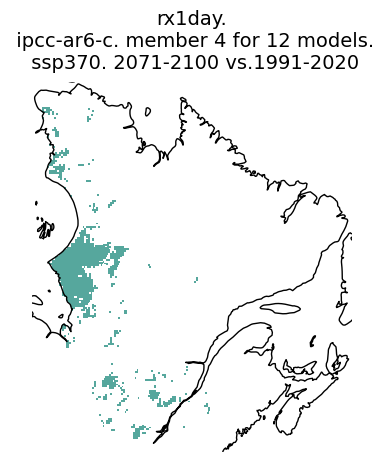

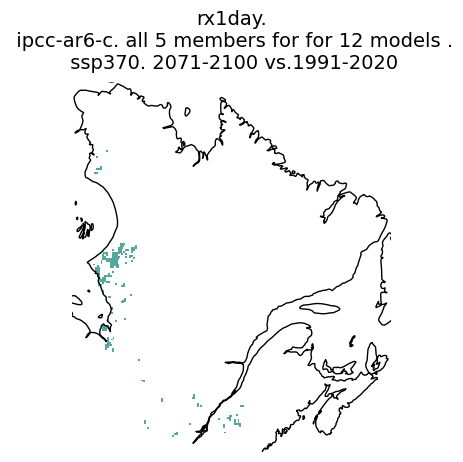

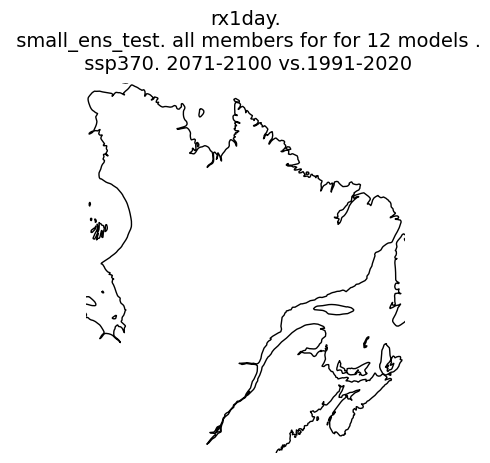

In [7]:
# rx1day

pref="1991-2020"
pfut='2071-2100'
var='rx1day'

idsnomem=[
    'ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_CORDEX_MPI-ESM1-2-LR_*_OURANOS_CRCM5-SN_ssp370_r1_NAM'
]

d={}
for sim_id in idsnomem:
    for f in glob.glob(f"{CONFIG['arches']}/rx1day/espo/rx1day_{sim_id}_espo.zarr.zip"):
        ds= xr.open_zarr(f)
        d[ds.attrs['cat:id']]=ds
ens=xc.ensembles.create_ensemble(d)
ens = stack_ensemble_member(ens)



# single member, one at the time, ipcc method
for i in range(5):
    ens1=ens.isel(member=i).squeeze()
    fractions = robustness_fractions(
        ens1[var].sel(time=slice(pfut[:4], pfut[-4:])),
        ens1[var].sel(time=slice(pref[:4], pref[-4:])),
        test="ipcc-ar6-c"
    )
    robustness = xc.ensembles.robustness_categories(fractions)
    nochange=robustness.where(robustness==2)    
    ax=fg.gridmap(nochange , plot_kw={'add_colorbar':False},features={"coastline":{'color':'black'}},)
    ax.set_title(f"{var}.\n ipcc-ar6-c. member {i} for 12 models.\n ssp370. {pfut} vs.{pref}")
    
# 5 members all together, ipcc method
ens1d=ens.stack(new_dim=["realization", "member"]).reset_index("new_dim").drop_vars(["realization", "member"])
ens1d=ens1d.rename({'new_dim':"realization"})
fractions = robustness_fractions(
    ens1d[var].sel(time=slice(pfut[:4], pfut[-4:])),
    ens1d[var].sel(time=slice(pref[:4], pref[-4:])),
    test="ipcc-ar6-c"
)
robustness = xc.ensembles.robustness_categories(fractions)
nochange=robustness.where(robustness==2)    
ax=fg.gridmap(nochange , plot_kw={'add_colorbar':False},features={"coastline":{'color':'black'}},)
ax.set_title(f"{var}.\n ipcc-ar6-c. all 5 members for for 12 models .\n ssp370. {pfut} vs.{pref}")

# small ensemble martin
fractions = robustness_fractions(
    ens[var].sel(time=slice(pfut[:4], pfut[-4:])),
    ens[var].sel(time=slice(pref[:4], pref[-4:])),
    test="small-ens-test"
)
robustness = xc.ensembles.robustness_categories(fractions)
nochange=robustness.where(robustness==2)    
ax=fg.gridmap(nochange , plot_kw={'add_colorbar':False},features={"coastline":{'color':'black'}},)
ax.set_title(f"{var}.\n small_ens_test. all members for for 12 models .\n ssp370. {pfut} vs.{pref}")



/tmp/ipykernel_2337795/892814870.py:29: FutureWarning: the `pandas.MultiIndex` object(s) passed as 'realization' coordinate(s) or data variable(s) will no longer be implicitly promoted and wrapped into multiple indexed coordinates in the future (i.e., one coordinate for each multi-index level + one dimension coordinate). If you want to keep this behavior, you need to first wrap it explicitly using `mindex_coords = xarray.Coordinates.from_pandas_multiindex(mindex_obj, 'dim')` and pass it as coordinates, e.g., `xarray.Dataset(coords=mindex_coords)`, `dataset.assign_coords(mindex_coords)` or `dataarray.assign_coords(mindex_coords)`.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espo

Text(0.5, 1.0, 'prcptot.\n small_ens_test. all 5 members for for 12 models .\n ssp370. 2021-2050 vs.1991-2020')

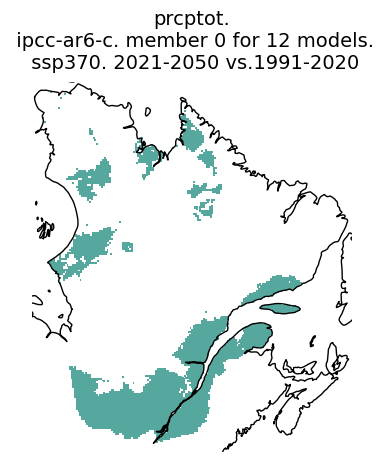

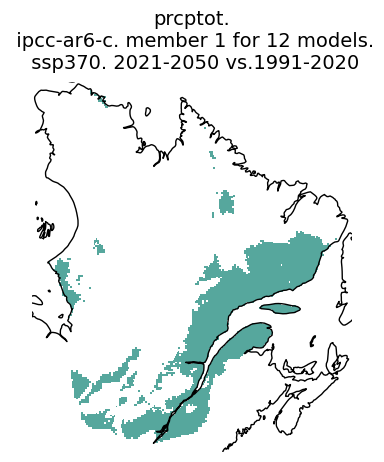

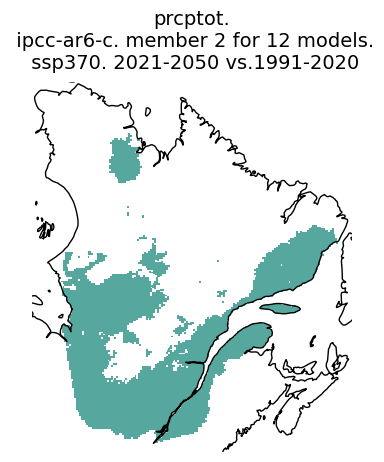

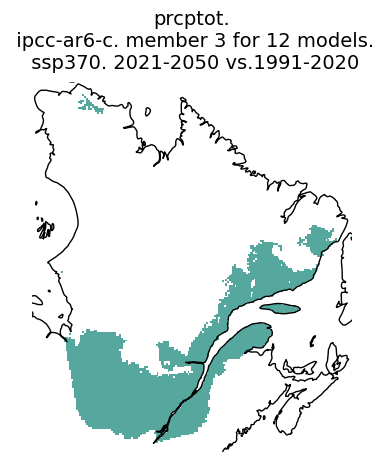

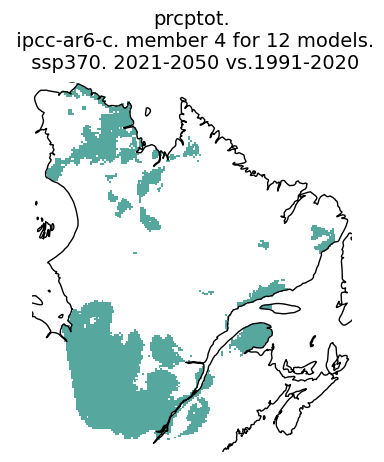

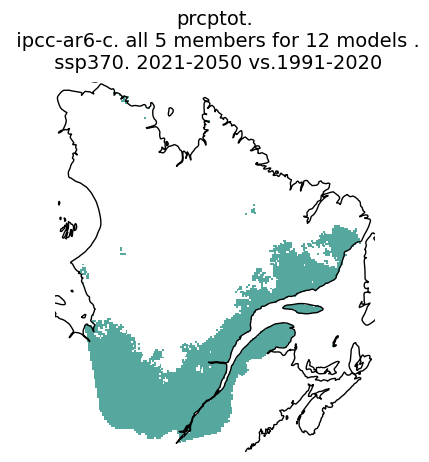

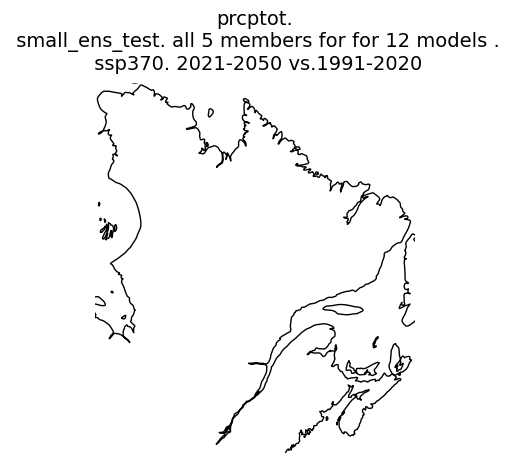

In [8]:
# prcptot

pref="1991-2020"
pfut='2021-2050'
var='prcptot'

idsnomem=[
    'ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_*_NAM',
    'ESPO_CaSR_CMIP6_CORDEX_MPI-ESM1-2-LR_*_OURANOS_CRCM5-SN_ssp370_r1_NAM'
]

d={}
for sim_id in idsnomem:
    for f in glob.glob(f"{CONFIG['arches']}/prcptot/espo/prcptot_{sim_id}_espo.zarr.zip"):
        ds= xr.open_zarr(f)
        d[ds.attrs['cat:id']]=ds
ens=xc.ensembles.create_ensemble(d)
ens = stack_ensemble_member(ens)




# single member, one at the time, ipcc method
for i in range(5):
    ens1=ens.isel(member=i).squeeze()
    fractions = robustness_fractions(
        ens1[var].sel(time=slice(pfut[:4], pfut[-4:])),
        ens1[var].sel(time=slice(pref[:4], pref[-4:])),
        test="ipcc-ar6-c"
    )
    robustness = xc.ensembles.robustness_categories(fractions)
    nochange=robustness.where(robustness==2)    
    ax=fg.gridmap(nochange , plot_kw={'add_colorbar':False},features={"coastline":{'color':'black'}},)
    ax.set_title(f"{var}.\n ipcc-ar6-c. member {i} for 12 models.\n ssp370. {pfut} vs.{pref}")
    
# 5 members all together, ipcc method
ens1d=ens.stack(new_dim=["realization", "member"]).reset_index("new_dim").drop_vars(["realization", "member"])
ens1d=ens1d.rename({'new_dim':"realization"})
fractions = robustness_fractions(
    ens1d[var].sel(time=slice(pfut[:4], pfut[-4:])),
    ens1d[var].sel(time=slice(pref[:4], pref[-4:])),
    test="ipcc-ar6-c"
)
robustness = xc.ensembles.robustness_categories(fractions)
nochange=robustness.where(robustness==2)    
ax=fg.gridmap(nochange , plot_kw={'add_colorbar':False},features={"coastline":{'color':'black'}},)
ax.set_title(f"{var}.\n ipcc-ar6-c. all 5 members for 12 models .\n ssp370. {pfut} vs.{pref}")

# small ensemble martin
fractions = robustness_fractions(
    ens[var].sel(time=slice(pfut[:4], pfut[-4:])),
    ens[var].sel(time=slice(pref[:4], pref[-4:])),
    test="small-ens-test"
)
robustness = xc.ensembles.robustness_categories(fractions)
nochange=robustness.where(robustness==2)    
ax=fg.gridmap(nochange , plot_kw={'add_colorbar':False},features={"coastline":{'color':'black'}},)
ax.set_title(f"{var}.\n small_ens_test. all 5 members for for 12 models .\n ssp370. {pfut} vs.{pref}")



In [ ]:
import xarray as xr
import xscen as xs
ds= xr.open_zarr('/project/ctb-frigon/julavoie/ESPO6-post2100/staging/simulation/biasadjusted/ESPO6-post2100_v2.0/CMIP6/ScenarioMIP/NAM-C3/NCC/NorESM2-MM/ssp585/r1i1p1f1/day/tasmax/tasmax_day_ESPO6_v20_CaSRv32+CMIP6_ScenarioMIP_NCC_NorESM2-MM_ssp585_r1i1p1f1_global_NAM-C3_1951-2298.zarr.zip')
xs.clean_up(ds, change_attr_prefix='')

/cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/MPI/gcc12/openmpi4/esmf/8.8.0/lib/python3.12/site-packages/esmpy/interface/loadESMF.py:94: VersionWarning: ESMF installation version 8.8.0, ESMPy version 8.8.0b0
  warnings.warn("ESMF installation version {}, ESMPy version {}".format(


# ensemble with multiple n members

In [ ]:
# rx1day

pref="1991-2020"
pfut='2071-2100'
var='rx1day'



d={}
for f in glob.glob(f"{CONFIG['arches']}/rx1day/espo/rx1day_*ssp370*_espo.zarr.zip"):
    ds= xr.open_zarr(f)
    d[ds.attrs['cat:id']]=ds
ens=xc.ensembles.create_ensemble(d)
ens = stack_ensemble_member(ens)

display(ens)


# 5 members all together, ipcc method
ens1d=ens.stack(new_dim=["realization", "member"]).reset_index("new_dim").drop_vars(["realization", "member"])
ens1d=ens1d.rename({'new_dim':"realization"})
fractions = robustness_fractions(
    ens1d[var].sel(time=slice(pfut[:4], pfut[-4:])),
    ens1d[var].sel(time=slice(pref[:4], pref[-4:])),
    test="ipcc-ar6-c"
)
robustness = xc.ensembles.robustness_categories(fractions)
nochange=robustness.where(robustness==2)    
ax=fg.gridmap(nochange , plot_kw={'add_colorbar':False},features={"coastline":{'color':'black'}},)
ax.set_title(f"{var}.\n ipcc-ar6-c. all 5 members for for 28 models .\n ssp370. {pfut} vs.{pref}")

# small ensemble martin
fractions = robustness_fractions(
    ens[var].sel(time=slice(pfut[:4], pfut[-4:])),
    ens[var].sel(time=slice(pref[:4], pref[-4:])),
    test="small-ens-test"
)
robustness = xc.ensembles.robustness_categories(fractions)
nochange=robustness.where(robustness==2)    
ax=fg.gridmap(nochange , plot_kw={'add_colorbar':False},features={"coastline":{'color':'black'}},)
ax.set_title(f"{var}.\n small_ens_test. all members for for 28 models .\n ssp370. {pfut} vs.{pref}")


# rx1day

pref="1991-2020"
pfut='2021-2100'
var='rx1day'



d={}
for f in glob.glob(f"{CONFIG['arches']}/rx1day/espo/rx1day_*ssp370*_espo.zarr.zip"):
    ds= xr.open_zarr(f)
    d[ds.attrs['cat:id']]=ds
ens=xc.ensembles.create_ensemble(d)
ens = stack_ensemble_member(ens)

display(ens)


# 5 members all together, ipcc method
ens1d=ens.stack(new_dim=["realization", "member"]).reset_index("new_dim").drop_vars(["realization", "member"])
ens1d=ens1d.rename({'new_dim':"realization"})
fractions = robustness_fractions(
    ens1d[var].sel(time=slice(pfut[:4], pfut[-4:])),
    ens1d[var].sel(time=slice(pref[:4], pref[-4:])),
    test="ipcc-ar6-c"
)
robustness = xc.ensembles.robustness_categories(fractions)
nochange=robustness.where(robustness==2)    
ax=fg.gridmap(nochange , plot_kw={'add_colorbar':False},features={"coastline":{'color':'black'}},)
ax.set_title(f"{var}.\n ipcc-ar6-c. all 5 members for for 28 models .\n ssp370. {pfut} vs.{pref}")

# small ensemble martin
fractions = robustness_fractions(
    ens[var].sel(time=slice(pfut[:4], pfut[-4:])),
    ens[var].sel(time=slice(pref[:4], pref[-4:])),
    test="small-ens-test"
)
robustness = xc.ensembles.robustness_categories(fractions)
nochange=robustness.where(robustness==2)    
ax=fg.gridmap(nochange , plot_kw={'add_colorbar':False},features={"coastline":{'color':'black'}},)
ax.set_title(f"{var}.\n small_ens_test. all members for for 28 models .\n ssp370. {pfut} vs.{pref}")




/tmp/ipykernel_2280765/892814870.py:29: FutureWarning: the `pandas.MultiIndex` object(s) passed as 'realization' coordinate(s) or data variable(s) will no longer be implicitly promoted and wrapped into multiple indexed coordinates in the future (i.e., one coordinate for each multi-index level + one dimension coordinate). If you want to keep this behavior, you need to first wrap it explicitly using `mindex_coords = xarray.Coordinates.from_pandas_multiindex(mindex_obj, 'dim')` and pass it as coordinates, e.g., `xarray.Dataset(coords=mindex_coords)`, `dataset.assign_coords(mindex_coords)` or `dataarray.assign_coords(mindex_coords)`.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/core.py:5200: PerformanceWarning: Increasing number of chunks by factor of 19
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/core.py:5200: PerformanceWarning: Increasing number of chunks by factor of 17


<xarray.Dataset> Size: 3GB
Dimensions:       (realization: 28, member: 5, rlat: 189, rlon: 162, time: 150)
Coordinates:
  * realization   (realization) object 224B 'ESPO_CaSR_CMIP6_CORDEX_CNRM-ESM2...
  * member        (member) int64 40B 0 1 2 3 4
  * rlat          (rlat) float32 756B -11.52 -11.43 -11.34 ... 5.22 5.31 5.4
  * rlon          (rlon) float32 648B 6.633 6.723 6.813 ... 20.94 21.03 21.12
    lat           (rlat, rlon) float32 122kB dask.array<chunksize=(10, 10), meta=np.ndarray>
    lon           (rlat, rlon) float32 122kB dask.array<chunksize=(10, 10), meta=np.ndarray>
    mask          (rlat, rlon) float64 245kB dask.array<chunksize=(10, 10), meta=np.ndarray>
    orog          (rlat, rlon) float32 122kB dask.array<chunksize=(10, 10), meta=np.ndarray>
  * time          (time) object 1kB 1951-01-01 00:00:00 ... 2100-01-01 00:00:00
    rotated_pole  int32 4B 1
Data variables:
    rx1day        (time, rlat, rlon, realization, member) float32 3GB dask.array<chunksize=(150, 10, 10, 1, 1), meta=np.ndarray>
Attributes: (12/32)
    avertissement:                Ouranos ne donne aucune garantie, expresse ...
    cat:_data_format_:            zarr
    cat:activity:                 ScenarioMIP
    cat:bias_adjust_institution:  Ouranos
    cat:bias_adjust_project:      ESPO
    cat:bias_adjust_reference:    CaSR
    ...                           ...
    intake_esm_dataset_key:       ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2...
    intake_esm_vars:              ['pr']
    license:                      Creative Commons Attribution 4.0 Internatio...
    organisation:                 Équipe science du climat et services climat...
    organization:                 Climate Science and Climate Services Team, ...
    version:                      v2.0

30


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-

<xarray.Dataset> Size: 3GB
Dimensions:       (realization: 28, member: 5, rlat: 189, rlon: 162, time: 150)
Coordinates:
  * realization   (realization) object 224B 'ESPO_CaSR_CMIP6_CORDEX_CNRM-ESM2...
  * member        (member) int64 40B 0 1 2 3 4
  * rlat          (rlat) float32 756B -11.52 -11.43 -11.34 ... 5.22 5.31 5.4
  * rlon          (rlon) float32 648B 6.633 6.723 6.813 ... 20.94 21.03 21.12
    lat           (rlat, rlon) float32 122kB dask.array<chunksize=(10, 10), meta=np.ndarray>
    lon           (rlat, rlon) float32 122kB dask.array<chunksize=(10, 10), meta=np.ndarray>
    mask          (rlat, rlon) float64 245kB dask.array<chunksize=(10, 10), meta=np.ndarray>
    orog          (rlat, rlon) float32 122kB dask.array<chunksize=(10, 10), meta=np.ndarray>
  * time          (time) object 1kB 1951-01-01 00:00:00 ... 2100-01-01 00:00:00
    rotated_pole  int32 4B 1
Data variables:
    rx1day        (time, rlat, rlon, realization, member) float32 3GB dask.array<chunksize=(150, 10, 10, 1, 1), meta=np.ndarray>
Attributes: (12/32)
    avertissement:                Ouranos ne donne aucune garantie, expresse ...
    cat:_data_format_:            zarr
    cat:activity:                 ScenarioMIP
    cat:bias_adjust_institution:  Ouranos
    cat:bias_adjust_project:      ESPO
    cat:bias_adjust_reference:    CaSR
    ...                           ...
    intake_esm_dataset_key:       ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2...
    intake_esm_vars:              ['pr']
    license:                      Creative Commons Attribution 4.0 Internatio...
    organisation:                 Équipe science du climat et services climat...
    organization:                 Climate Science and Climate Services Team, ...
    version:                      v2.0

30


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-

# rx1day test ipcc vs portraits

In [20]:
#ipcc atlas

def rx1day_rob(
    ref,
    fut,
    n_members,
    other_search_criteria,
    typ,
    test,
    letter):


    typname={'reg1deg': '1deg', 'reg10km':'10km', 'espo':'ESPO'}
    levname={'reg1deg': 'raw', 'reg10km':'raw', 'espo':'adjusted'}

    sim_dict =xs.search_data_catalogs(
        data_catalogs=cat,
        variables_and_freqs={'pr':'D'},
        restrict_members={'ordered':n_members},
        other_search_criteria=other_search_criteria
    )
    
    n_sources=len(set([str(v.df['source'].unique()[0]) for  k,v in sim_dict.items()]))
    
    datasets=[]
    delta_datasets=[]
    for sim_id in sim_dict.keys():
        sim_id = sim_id.replace(".NAM.biasadjusted.D", "")
        ds= xr.open_zarr(f"{CONFIG['arches']}/rx1day/{typ}/rx1day_{sim_id}_{typ}.zarr.zip")
        datasets.append(ds)
    
    ens = xc.ensembles.create_ensemble(datasets)
    #fractions = xc.ensembles.robustness_fractions(ens.rx1day.sel(time=slice(fut[:4], fut[-4:])),ens.rx1day.sel(time=slice(ref[:4], ref[-4:])), test="ipcc-ar6-c")
    fractions = robustness_fractions(ens.rx1day.sel(time=slice(fut[:4], fut[-4:])),ens.rx1day.sel(time=slice(ref[:4], ref[-4:])), test=test)
    robustness = xc.ensembles.robustness_categories(fractions)
    nochange=robustness.where(robustness==2)
    conflict=robustness.where(robustness==3)
    
    
    ax=fg.gridmap(nochange , plot_kw={'add_colorbar':False},features={"coastline":{'color':'black'}},)
    ax.set_title(f"{letter}) max {n_members} members of {n_sources} {levname[typ]} GCMs.\n {test} test. {typname[typ]} grid. \n {fut} vs.{ref}")
    plt.savefig(f"{CONFIG['figures']}/rx1day_{test}_{n_members}mem_{n_sources}mod_{typ}_{ref}_{fut}.pdf",bbox_inches='tight')


2026-08-27 14:03:12 INFO     xscen.extract   Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


INFO:xscen.extract:Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


2026-08-27 14:03:12 INFO     xscen.extract   288 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP'}.


INFO:xscen.extract:288 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP'}.


2026-08-27 14:03:12 INFO     xscen.extract   Iterating over 72 potential datasets.


...

INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


2026-08-27 14:05:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


2026-08-27 14:05:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: Runti

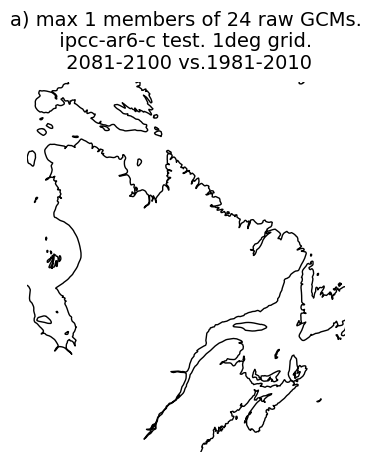

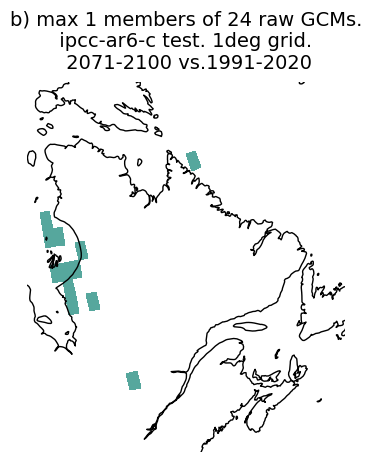

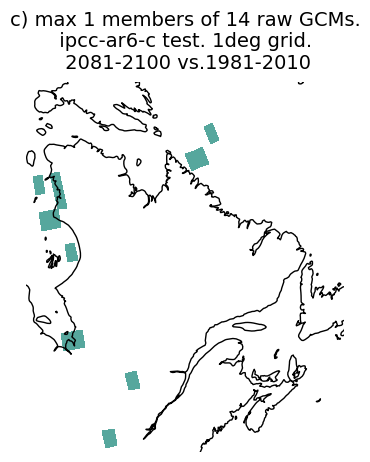

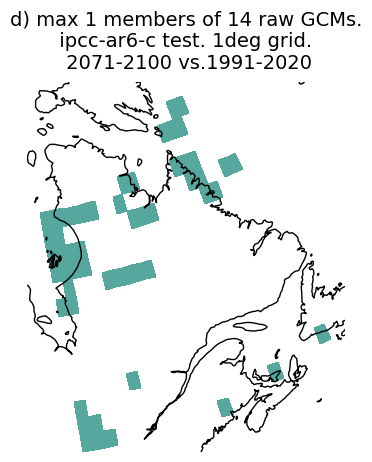

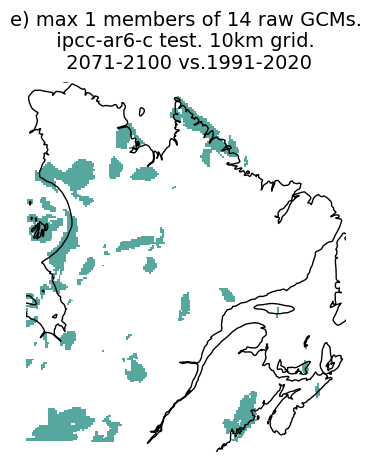

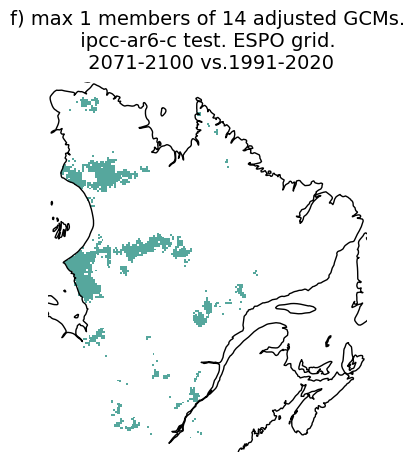

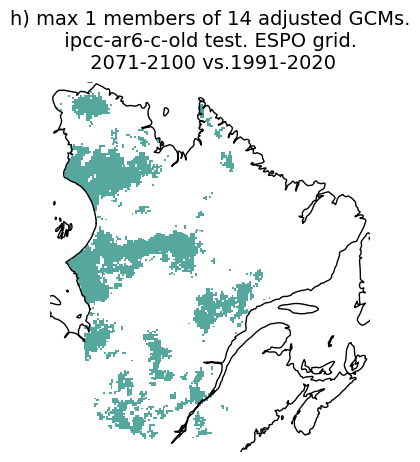

In [23]:
#new method
rx1day_rob(
    ref="1981-2010",
    fut='2081-2100',
    n_members=1,
    other_search_criteria=dict(bias_adjust_project="ESPO", experiment="ssp370",activity='ScenarioMIP'),
    typ='reg1deg',
    test="ipcc-ar6-c",
    letter='a')

# portrait period
rx1day_rob(
    ref="1991-2020",
    fut='2071-2100',
    n_members=1,
    other_search_criteria=dict(bias_adjust_project="ESPO", experiment="ssp370",activity='ScenarioMIP'),
    typ='reg1deg',
    test="ipcc-ar6-c",
    letter='b',
)
# hausfather , ipcc periods
rx1day_rob(
    ref="1981-2010",
    fut='2081-2100',
    n_members=1,
    other_search_criteria=dict(bias_adjust_project="ESPO", experiment="ssp370",activity='ScenarioMIP',
                              source=['ACCESS-CM2','ACCESS-ESM1-5','BCC-CSM2-MR','CMCC-ESM2','CNRM-CM6-1','CNRM-ESM2-1','FGOALS-g3','GFDL-ESM4',
                                    'MIROC6','MIROC-ES2L','MPI-ESM1-2-HR','MPI-ESM1-2-LR','MRI-ESM2-0','NorESM2-LM',]),
    typ='reg1deg',
    test="ipcc-ar6-c",
    letter='c',
)

# hausfather ,portraits periods
rx1day_rob(
    ref="1991-2020",
    fut='2071-2100',
    n_members=1,
    other_search_criteria=dict(bias_adjust_project="ESPO", experiment="ssp370",activity='ScenarioMIP',
                              source=['ACCESS-CM2','ACCESS-ESM1-5','BCC-CSM2-MR','CMCC-ESM2','CNRM-CM6-1','CNRM-ESM2-1','FGOALS-g3','GFDL-ESM4',
                                    'MIROC6','MIROC-ES2L','MPI-ESM1-2-HR','MPI-ESM1-2-LR','MRI-ESM2-0','NorESM2-LM',]),
    typ='reg1deg',
    test="ipcc-ar6-c",
    letter='d',
)

# hausfather , portraits periods, 10km
rx1day_rob(
    ref="1991-2020",
    fut='2071-2100',
    n_members=1,
    other_search_criteria=dict(bias_adjust_project="ESPO", experiment="ssp370",activity='ScenarioMIP',
                              source=['ACCESS-CM2','ACCESS-ESM1-5','BCC-CSM2-MR','CMCC-ESM2','CNRM-CM6-1','CNRM-ESM2-1','FGOALS-g3','GFDL-ESM4',
                                    'MIROC6','MIROC-ES2L','MPI-ESM1-2-HR','MPI-ESM1-2-LR','MRI-ESM2-0','NorESM2-LM',]),
    typ='reg10km',
    test="ipcc-ar6-c",
    letter='e',
)

# hausfather , portraits periods, espo
rx1day_rob(
    ref="1991-2020",
    fut='2071-2100',
    n_members=1,
    other_search_criteria=dict(bias_adjust_project="ESPO", experiment="ssp370",activity='ScenarioMIP',
                              source=['ACCESS-CM2','ACCESS-ESM1-5','BCC-CSM2-MR','CMCC-ESM2','CNRM-CM6-1','CNRM-ESM2-1','FGOALS-g3','GFDL-ESM4',
                                    'MIROC6','MIROC-ES2L','MPI-ESM1-2-HR','MPI-ESM1-2-LR','MRI-ESM2-0','NorESM2-LM',]),
    typ='espo',
    test="ipcc-ar6-c",
    letter='f',
)

# hausfather , portraits periods, espo, OLD
rx1day_rob(
    ref="1991-2020",
    fut='2071-2100',
    n_members=1,
    other_search_criteria=dict(bias_adjust_project="ESPO", experiment="ssp370",activity='ScenarioMIP',
                              source=['ACCESS-CM2','ACCESS-ESM1-5','BCC-CSM2-MR','CMCC-ESM2','CNRM-CM6-1','CNRM-ESM2-1','FGOALS-g3','GFDL-ESM4',
                                    'MIROC6','MIROC-ES2L','MPI-ESM1-2-HR','MPI-ESM1-2-LR','MRI-ESM2-0','NorESM2-LM',]),
    typ='espo',
    test="ipcc-ar6-c-old",
    letter='h',
)